# TP noté R5.11 : régression puis classification

**Durée : 1h30. Barème sur 20 : partie 1 sur 13 points, partie 2 sur 7 points. Une question bonus (1 point) figure à la fin.**

Vous avez le droit d'utiliser tous vos notebooks de TP précédents, ainsi que la documentation de NumPy, scikit-learn, PyTorch et matplotlib. Le travail est individuel. **Tout recours à une IA est strictement interdit et donnera lieu à une procédure disciplinaire.**

Ce notebook comporte deux parties indépendantes. Si vous bloquez sur la première, passez à la seconde. Complétez les cellules marquées « A vous de jouer » et rédigez vos réponses dans les cellules de texte prévues. **Les cellules déjà remplies sont à exécuter telles quelles.**

**Avant de commencer :** sélectionnez l'interpréteur Python de `/opt/pytorch-env` comme kernel, comme lors des TP précédents.

À rendre en fin de séance : ce notebook complété, avec toutes les cellules exécutées (les sorties et graphiques doivent être visibles).

## Partie 1 : Régression, consommation d'une voiture selon son poids (13 points)

On étudie le jeu de données `mpg` : des mesures sur des voitures, dont leur **poids** (en kg) et leur **consommation** (en litres aux 100 km). On souhaite prédire la consommation d'une voiture à partir de son poids.

La cellule ci-dessous charge et prépare les données pour vous : vous n'avez rien à modifier. Elle définit la fonction `charger_donnees()` qui renvoie deux tableaux NumPy de même taille, `poids` (en kg) et `conso` (en L/100 km).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def charger_donnees():
    """Charge le jeu mpg, convertit les unités et supprime les lignes incomplètes.
    Renvoie (poids en kg, consommation en L/100 km), deux tableaux NumPy 1D."""
    df = sns.load_dataset("mpg").dropna(subset=["weight", "mpg"])
    #df = pd.read_csv("data/mpg.csv").dropna(subset=["weight", "mpg"])
    poids = df["weight"].values * 0.453592371        # livres -> kilogrammes
    conso = 235.215 / df["mpg"].values              # miles/gallon -> litres/100 km
    return poids, conso

poids, conso = charger_donnees()
print(poids.shape, conso.shape)

(398,) (398,)


**Question 1 (2 points).** Affichez le nuage de points de la consommation en fonction du poids (axes nommés avec leurs unités). Décrivez en une phrase la relation que vous observez.

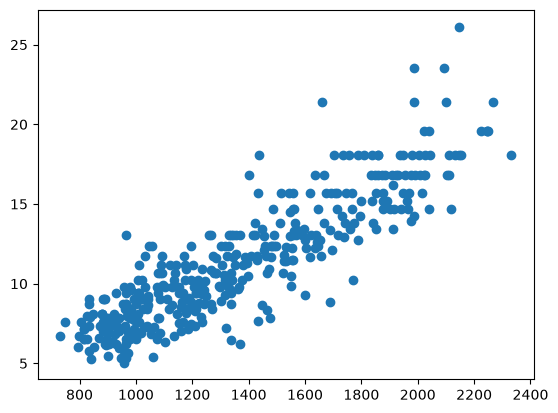

In [ ]:
# A vous de jouer
plt.scatter(poids,conso)

*Votre réponse :*

In [ ]:
"""Plus le ploids est plus grand plus le voiture consomme """

**Question 2 (6 points).** Apprenez une régression linéaire $\text{conso} = w_0 + w_1 \times \text{poids}$ sur **l'ensemble des données**. Vous êtes libre de la méthode : descente de gradient écrite à la main avec NumPy, `LinearRegression` de scikit-learn, ou PyTorch.

*Conseil : pensez à normaliser vos données, comme au TD5.*

In [53]:
# A vous de jouer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

x = poids.reshape(-1, 1)
t = conso.reshape(-1,1)

scaler_x = StandardScaler()
scaler_t = StandardScaler()

x_norm = scaler_x.fit_transform(x)
t_norm = scaler_t.fit_transform(t)


model = LinearRegression()
model.fit(x_norm, t_norm)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.89]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[19.95]


**Question 3 (0,5 point).** Affichez les valeurs obtenues pour $w_0$ et $w_1$.

In [54]:
# A vous de jouer
w0= model.intercept_[0]
w1 = model.coef_[0][0]
print(f'sklearn LinearRegression : w0 = {w0}, w1 = {w1}')

sklearn LinearRegression : w0 = 5.543075191765971e-16, w1 = 0.8852185596531802


**Question 4 (1 point).** Superposez sur un même graphique le nuage de points et la droite de régression apprise.

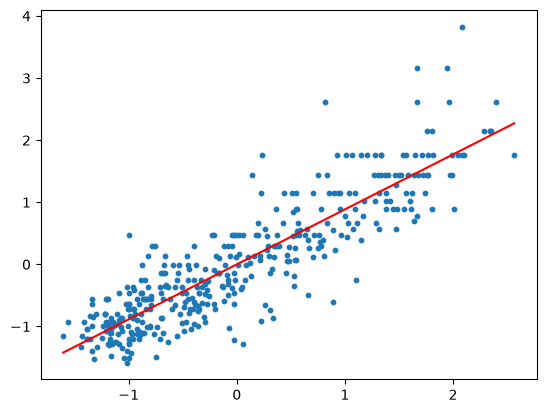

In [55]:
# A vous de jouer
plt.scatter(x_norm, t_norm,s=10)
xs = np.linspace(x_norm.min(),x_norm.max(), 100)
plt.plot(xs, w0 + w1*xs,color="red")


**Question 5 (2 points).** Calculez l'erreur quadratique moyenne (MSE) de votre modèle sur l'ensemble des données et affichez-la.

0.21638810164554834


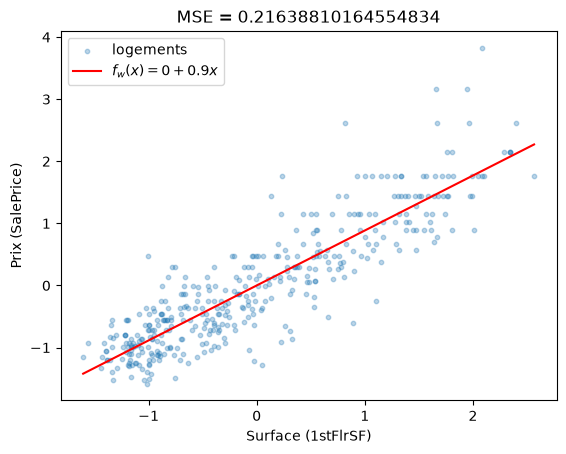

np.float64(0.21638810164554834)

In [ ]:
# A vous de jouer
def MSE(y, t):
    err = (y-t) **2
    return np.sum(err) / t.size


def plot_model(w0, w1, x=x_norm, t=t_norm):
    y = w0 + w1 * x
    loss = MSE(y, t)
    fig, ax = plt.subplots()
    ax.scatter(x, t, s=10, alpha=0.3, label='logements')
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, w0 + w1 * x_line, 'r-', label=f'$f_w(x)={w0:.0f}+{w1:.1f}x$')
    ax.set_xlabel('Surface (1stFlrSF)'); ax.set_ylabel('Prix (SalePrice)')
    ax.set_title(f'MSE = {loss}')
    ax.legend()
    plt.show()
    return loss

plot_model(w0,w1)

**Question 6 (1,5 point).** Utilisez votre modèle pour prédire la consommation d'une voiture de 1 500 kg. Interprétez le résultat en une phrase.

In [ ]:
# A vous de jouer


*Votre interprétation :*

## Partie 2 : Classification avec PyTorch, parcelles agricoles (7 points)

**Dans cette partie, vous devez utiliser PyTorch** (pas de modèle scikit-learn pour l'apprentissage).

Un agronome suit des parcelles de culture. Pour chaque parcelle, il a relevé la **dose d'azote** apportée (en kg par hectare) et la **pluie** tombée dans le mois (en mm), et il a noté si la parcelle est **saine** (étiquette 1) ou **en stress** (étiquette 0). On veut prédire l'état d'une parcelle à partir de ces deux mesures.

La cellule suivante génère les données (ne la modifiez pas). Elle renvoie les mesures `X` (une ligne par parcelle : azote, pluie) et les étiquettes `y`.

In [63]:
import torch
import torch.nn as nn

def generer_parcelles(n=300, graine=42):
    rng = np.random.default_rng(graine)
    azote = rng.uniform(0, 200, n)     # kg d'azote par hectare
    pluie = rng.uniform(0, 100, n)     # mm de pluie sur le mois
    seuil = 12 + 0.0098 * (azote - 100) ** 2
    saine = (pluie - seuil + rng.normal(0, 8, n) > 0).astype(np.float32)
    return np.c_[azote, pluie].astype(np.float32), saine

X, y = generer_parcelles()
print(X.shape, y.shape)

(300, 2) (300,)


**Question 7 (2 points).** Séparez les données en un jeu d'entraînement (70 %) et un jeu de test (30 %), avec une graine aléatoire fixée à 0 (`random_state=0`) pour que vos résultats soient reproductibles. Affichez la taille de chaque jeu. Vous nommerez vos variables `X_tr`, `X_te`, `y_tr`, `y_te` pour la suite.

In [70]:
# A vous de jouer
from sklearn.model_selection import train_test_split


X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)

**Question 8 (1 point).** Affichez le nuage de points des parcelles d'entraînement (azote en abscisse, pluie en ordonnée), avec une couleur par classe. Que pouvez-vous dire de la façon dont les deux classes sont réparties dans le plan ?

ValueError: x and y must be the same size

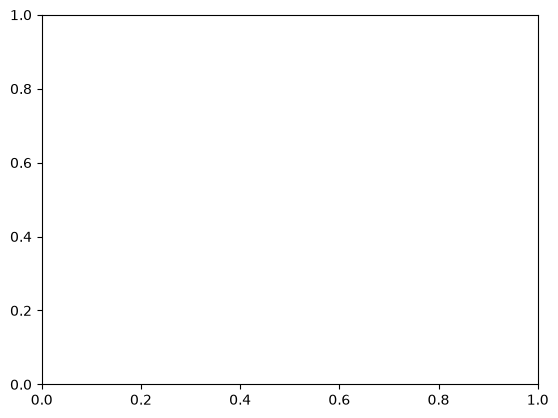

In [ ]:
# A vous de jouer

#plt.scatter(X_tr , y_tr)

*Votre réponse :*

**Question 9 (3 points).** Construisez, entraînez avec PyTorch, puis évaluez un modèle de classification de votre choix (architecture, fonction d'erreur, nombre d'itérations et pas d'apprentissage à choisir). Affichez l'évolution de la perte au cours de l'entraînement et la **précision (accuracy) sur le jeu de test**.

*Essayez plusieurs architectures et comparez-les en rendant compte de toutes vos traces d'expériences.*

In [ ]:
# A vous de jouer


**Question 10 (1 point).** Indiquez ci-dessous le **meilleur score de précision sur le jeu de test** que vous avez obtenu, l'architecture correspondante, et en une ou deux phrases ce qui a le plus amélioré vos résultats au cours de vos essais.

*Votre réponse :*

## Question bonus

**Question 11 (bonus, 1 point).** Visualisez la frontière de décision apprise par votre modèle, superposée aux points de test.

In [ ]:
# A vous de jouer
